# INI CODE DI KASIH ASLAB

In [12]:
import numpy as np
from scipy.io import wavfile
import scipy.fftpack as fft
from scipy.signal import get_window
import matplotlib.pyplot as plt

TRAIN_PATH = 'sample.wav'
sample_rate, audio = wavfile.read(TRAIN_PATH)
if audio.ndim > 1:
    audio = np.mean(audio, axis=1)

#Normalization
#Menormalisasi value level amplitudo menjadi -1 hingga 1
audio = audio / np.max(np.abs(audio))

#Frame Blocking
#TODO add description what it do
FFT_SIZE = 2048 # Value bebas, bisa disesuaikan dengan result yang diinginkan
HOP_SIZE = 15 # Value bebas, bisa disesuaikan dengan result yang diinginkan

pad_width = int(FFT_SIZE / 2) # Formulanya bebas
audio = np.pad(audio, pad_width, mode = 'reflect')
HOP_LENGTH  = np.round(sample_rate * HOP_SIZE / 1000).astype(int)
frame_num = ((len(audio) - FFT_SIZE) // HOP_LENGTH ) + 1

frames = np.zeros((frame_num, FFT_SIZE))

for i in range(frame_num):
 start = i * HOP_LENGTH
 end = start + FFT_SIZE
 frames[i] = audio[start : end]

#Windowing
#TODO add description what it do
#audio yang periodic (dari hasil framing) dibuat menjadi continuous dengan membuat ujung awal dan akhir signal mendekati 0 sehingga tidak ada lompatan nilai / distorsi
window_type = "hann"
window = get_window(window_type, FFT_SIZE, fftbins = True)

audio_win = frames * window

#FFT
#Mengubah audio dari time dimension ke frequency dimension
audio_winT = np.transpose(audio_win)
audio_fft = np.empty((1 + FFT_SIZE//2, audio_winT.shape[1]), dtype=np.complex64)

for i in range(audio_fft.shape[1]):
    fft_result = fft.fft(audio_winT[:, i])
    audio_fft[:, i] = fft_result[:audio_fft.shape[0]]

audio_fft = np.transpose(audio_fft)
audio_power = np.square(np.abs(audio_fft))

# mulai dari sini coding sendiri

In [14]:
# Mel Filter Bank
# Fungsi freq spectrum menjadi mel spectrum

# berapa filter mel yang ingin dipakai dan total mfcc yang ingi diambil

NUM_MEL_FILTERS = 40
NUM_MFCC = 13


# freq range
LOW_FREQ = 0
HIGH_FREQ = sample_rate / 2

# 2 function untuk mengubah hz ke mel dan merubah mel ke hz

def hz_to_mel(hz):
    return 2595 * np.log10(1 + hz/700)

def mel_to_hz(mel):
    return 700 * (10 ** (mel/2595) - 1)



# mengubah range yang tadi nya hz menjadi mel
low_mel = hz_to_mel(LOW_FREQ)
high_mel = hz_to_mel(HIGH_FREQ)



# membuat sebuah mel scale
# NUM_MEL_FILTERS harus di + 2 agar jarak kiri kanan sama
mel_points = np.linspace(low_mel, high_mel, NUM_MEL_FILTERS + 2)


# titik mel menjadi hz kembali
hz_points = mel_to_hz(mel_points)


# mengubah freq hz menjadi posisi fft
bin_points = np.floor((FFT_SIZE + 1) * hz_points / sample_rate).astype(int)
print(len(bin_points))

# Batasi bin_points agar tidak melewati indeks maksimum:
bin_points = np.clip(
    bin_points,
    0, 
    FFT_SIZE // 2
)

print(len(bin_points))

# membuat filter mel bank
# rumus FFT_SIZE // 2 + 1 = jumlah freq yang digunakan
mel_filters = np.zeros((NUM_MEL_FILTERS, FFT_SIZE // 2 + 1))

print(len(bin_points))

for m in range(1, NUM_MEL_FILTERS + 1):
    # menentukan batas kiri, kanan dan tengah filter
    left = bin_points[m-1]
    right = bin_points[m+1]
    mid = bin_points[m]
    
    # bagian kiri, bakal naik dari angka 0 ke 1
    for k in range(left, mid):
        if mid != left:
            mel_filters[m-1, k] = ( # [m-1, k] maksudnya row ke m-1, column ke k. penulisan gitu karena numpy butuh [a, b] instead of [a][b]
                (k - left) / (mid - left)
            )
            
    # bagian kanan, bakal turun dari angka 1 ke 0
    for k in range(mid, right):
        if right != mid:
            mel_filters[m-1, k] = (
                (right - k) / (right - mid)
            )
            
            

# apply mel filter bank
mel_energy = np.dot(audio_power, mel_filters.T)


# logarithm
# validasi pertama harus menghindari log(0)
mel_energy = np.where(
    mel_energy == 0,
    np.finfo(float).eps,
    mel_energy
)

# mengubah energy nya menjadi log scale
log_mel_energy = np.log(mel_energy)


# DCT -> log mel energy jadi MFCC
mfcc = fft.dct(
    log_mel_energy,
    type = 2, #dcty type two
    axis = 1,
    norm = 'ortho' # normalisasi hasil dct
)

# mengambil mfcc 13 pertama
mfcc = mfcc[:, :NUM_MFCC]

print("MFCC Shape: ", mfcc.shape)
print(mfcc)

42
42
42
MFCC Shape:  (2001, 13)
[[-26.23559014   5.88828113   5.23271109 ...   0.65705526   0.71053172
    1.52857097]
 [-26.11541998   5.94819994   5.18356848 ...   0.70990744   0.69165698
    1.41875359]
 [-25.94728609   6.00070871   5.11099749 ...   0.86946344   0.72878754
    1.19093979]
 ...
 [-60.86947186   8.11558875   1.26722245 ...   0.18334564   0.53278448
   -0.24926989]
 [-66.71168918   6.60276623   2.61642486 ...   0.72134145   0.18806001
   -0.08694287]
 [-70.27211276   5.39070913   3.45715509 ...   1.12524203   0.30174172
    0.15800233]]


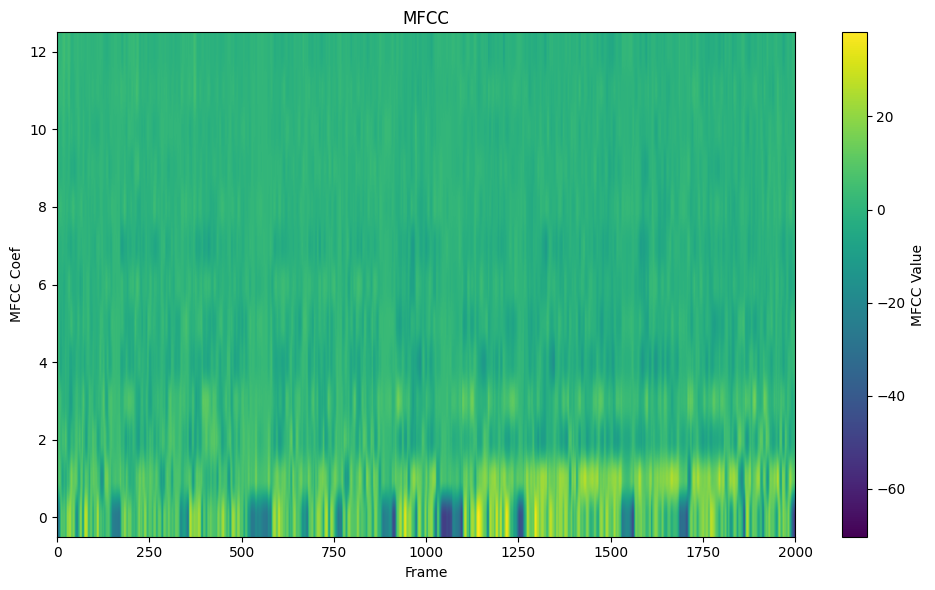

In [15]:
# plotting
plt.figure(figsize=(10, 6))

plt.imshow(
    mfcc.T,
    aspect='auto',
    origin='lower',
    cmap='viridis'
)

plt.colorbar(label="MFCC Value")
plt.xlabel("Frame")
plt.ylabel("MFCC Coef")
plt.title("MFCC")
plt.tight_layout()
plt.show()